# Lasair Demo Notebook

## Basic configuration
Uses HyraxLoopback model to ensure that that all the components are hooked up correctly.

In [ ]:
from hyrax_alerts.process_alerts import process_alerts

process_alerts(config_filepath="./lasair_test_config.toml")

## HyraxTs2Vec Model
Uses pretrained HyraxTs2Vec model for time series representation learning.

In [1]:
from hyrax_alerts.process_alerts import process_alerts

process_alerts(config_filepath="./lasair_ts2vec_config.toml")

All migrations complete. Your configuration file is now up to date with the latest schema. The runtime config saved in the output directory will reflect the new schema, and your original config file will remain unchanged on disk.
Runtime config contains key or section 'writers' which has no default defined. All configuration keys and sections must be defined in /home/drew/code/hyrax/src/hyrax/hyrax_default_config.toml
[2026-11-20 13:27:23,925 hyrax.alerts.writers.writer_utils:INFO] Created writer 'to_disk_0' of class 'HyraxAlertsDiskWriter'
[2026-11-20 13:27:23,939 hyrax.models.model_registry:WARNING] Both model and config define an optimizer. Hyrax will use self.optimizer defined in the model.
[2026-11-20 13:27:23,940 hyrax.models.model_registry:INFO] Using self.optimizer defined in model: torch.optim.adamw.AdamW
[2026-11-20 13:27:23,940 hyrax.models.model_registry:WARNING] Both model and config define a criterion. Hyrax will use self.criterion defined in the model.
[2026-11-20 13:27:

Example pre-filtering function called.
Example pre-processing function called.
Example post-processing function called.
Example post-filtering function called.


[2026-11-20 13:27:45,171 hyrax.alerts.process_alerts:INFO] Processing batch 2 with size 132


Example pre-filtering function called.
Example pre-processing function called.
Example post-processing function called.
Example post-filtering function called.


[2026-11-20 13:27:50,318 hyrax.alerts.process_alerts:INFO] Processing batch 3 with size 135


Example pre-filtering function called.
Example pre-processing function called.
Example post-processing function called.
Example post-filtering function called.


[2026-11-20 13:28:00,476 hyrax.alerts.process_alerts:INFO] Processing batch 4 with size 139
[2026-11-20 13:28:00,476 hyrax.alerts.process_alerts:INFO] Alert limit of 500 reached. Stopping processing.
[2026-11-20 13:28:00,477 hyrax.datasets.kafka_stream_dataset:INFO] Kafka partitions revoked: ['lasair_201DrewsLSSTvariables[0]', 'lasair_201DrewsLSSTvariables[1]', 'lasair_201DrewsLSSTvariables[2]', 'lasair_201DrewsLSSTvariables[3]', 'lasair_201DrewsLSSTvariables[4]', 'lasair_201DrewsLSSTvariables[5]', 'lasair_201DrewsLSSTvariables[6]', 'lasair_201DrewsLSSTvariables[7]']
[2026-11-20 13:28:00,637 hyrax.datasets.result_dataset:INFO] Optimizing Lance table after 3 batches
[2026-11-20 13:28:00,662 hyrax.datasets.result_dataset:INFO] Lance table optimization complete
[2026-11-20 13:28:00,667 hyrax.verbs.infer_stream:INFO] InferStream session closed.


Example pre-filtering function called.
Example pre-processing function called.


In [2]:
from hyrax import Hyrax
from hyrax.config_utils import find_most_recent_results_dir

h = Hyrax()

infer_dir = find_most_recent_results_dir(h.config, "infer_stream")
umap_results = h.umap(input_dir=infer_dir)

[2026-11-20 13:28:00,726 hyrax.verbs.umap:WARNING] The `umap` verb is deprecated. Use `reduce_dimensions(algorithm='umap')` instead.
[2026-11-20 13:28:02,120 hyrax.verbs.reduce_dimensions:INFO] Saving reduction results using umap to /home/drew/code/hyrax_alerts/docs/pre_executed/results/20261120-132802-umap-WGF9
[2026-11-20 13:28:02,120 hyrax.verbs.reduce_dimensions:INFO] Using most recent inference results dataset for dimensionality reduction.
[2026-11-20 13:28:02,428 hyrax.verbs.reduce_dimensions:INFO] No model_path specified. A new model will be fitted.
[2026-11-20 13:28:02,429 hyrax.verbs.reduction_algorithms.umap:INFO] Fitting the UMAP
[2026-11-20 13:28:08,169 hyrax.verbs.reduce_dimensions:INFO] Saving fitted umap reducer to result directory


Creating lower dimensional representation using UMAP::   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-20 13:28:10,826 hyrax.datasets.result_dataset:INFO] Optimizing Lance table after 1 batches
[2026-11-20 13:28:10,830 hyrax.datasets.result_dataset:INFO] Lance table optimization complete
[2026-11-20 13:28:10,831 hyrax.verbs.reduce_dimensions:INFO] Finished transforming all data with umap


In [3]:
import numpy as np

# Stack all UMAP embeddings into a single array.
umap_embeddings = np.array([umap_results[i]["data"] for i in range(len(umap_results))])
print(f"Shape: {umap_embeddings.shape}  (samples × components)")

Shape: (406, 2)  (samples × components)


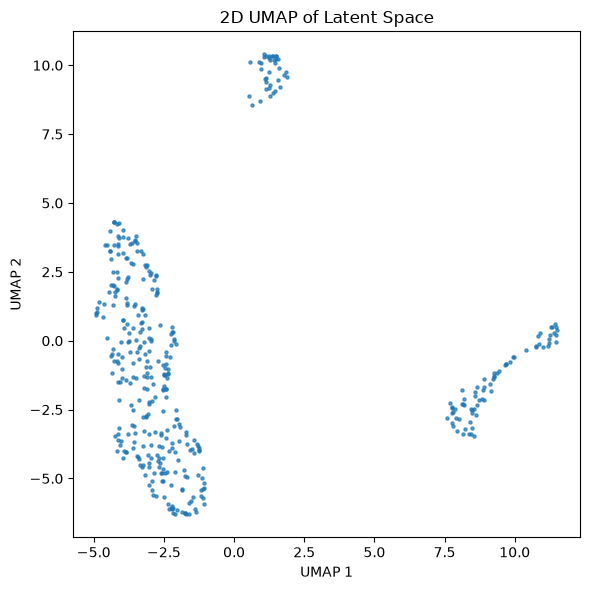

In [4]:
import matplotlib.pyplot as plt

# find all values in the first dimension that are not 9.220365
filtered_umap_embeddings = umap_embeddings[umap_embeddings[:, 0] != 9.220365]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(filtered_umap_embeddings[:, 0], filtered_umap_embeddings[:, 1], s=5, alpha=0.7)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("2D UMAP of Latent Space")
plt.tight_layout()
plt.show()